In [ ]:
# PuLP 3 mantiene la API usada por este modelo e incluye el solver CBC.
%pip install --quiet "pulp>=3,<4" numpy matplotlib


Note: you may need to restart the kernel to use updated packages.


ESTADO DE LA SOLUCIÓN: Optimal
Módulos con Protocolo Previo (x1*) : 6.00 módulos
Módulos con Prompting Directo (x2*) : 4.00 módulos
Total Módulos Entregados           : 10.00 módulos
Deuda Técnica Mínima (Z*)          : 3150.00 minutos de remediación
Equivalente en horas de deuda      : 52.50 horas

ANÁLISIS DE RESTRICCIONES (HOLGURAS Y PRECIOS SOMBRA DUALES)
Restricción : Meta_Modulos             | Holgura =  -0.00 | Precio Sombra (Pi) =   900.00
Restricción : Presupuesto_Tiempo       | Holgura =  -0.00 | Precio Sombra (Pi) =  -112.50
Restricción : Capacidad_Especificacion | Holgura =   2.00 | Precio Sombra (Pi) =     0.00


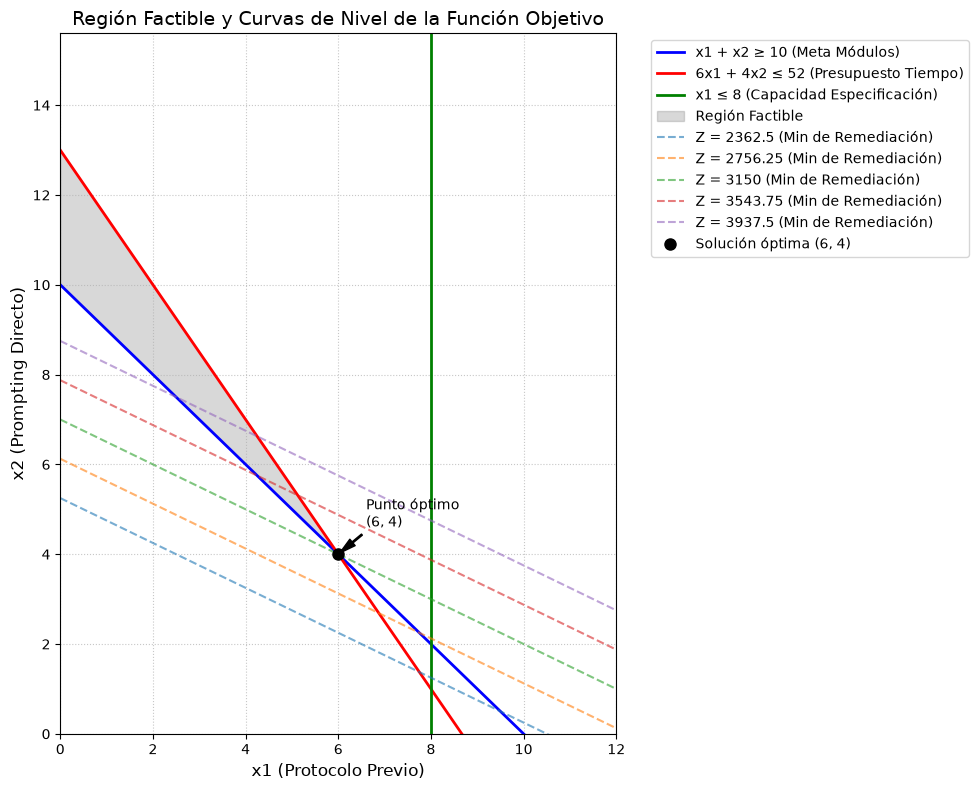

In [8]:
"""
Modelo de Programación Lineal (PL) - Tesis Doctoral (Hipótesis 1)
Estudiante: Alejandro Aldas
"""

import pulp
import numpy as np
import matplotlib.pyplot as plt

# Parámetros compartidos por el modelo y el gráfico.
deuda_protocolo = 225.0
deuda_prompting = 450.0
meta_modulos = 10.0
tiempo_protocolo = 6.0
tiempo_prompting = 4.0
presupuesto_tiempo = 52.0
capacidad_especificacion = 8.0

# 1. Instanciar el problema de Minimización
modelo = pulp.LpProblem("Minimizar_Deuda_Tecnica_Codigo_D1", pulp.LpMinimize)

# 2. Definición de Variables de Decisión (Continuas >= 0)
x1 = pulp.LpVariable("x1_Protocolo_Previo", lowBound=0, cat='Continuous')
x2 = pulp.LpVariable("x2_Prompting_Directo", lowBound=0, cat='Continuous')

# 3. Función Objetivo: Minimizar minutos de remediación (SonarQube RemMin)
modelo += deuda_protocolo * x1 + deuda_prompting * x2, "Deuda_Tecnica_Total_RemMin"

# 4. Restricciones Lineales
# R1: Meta mínima institucional de módulos
modelo += (x1 + x2 >= meta_modulos), "Meta_Modulos"

# R2: Presupuesto de tiempo total de desarrollo (horas)
modelo += (tiempo_protocolo * x1 + tiempo_prompting * x2 <= presupuesto_tiempo), "Presupuesto_Tiempo"

# R3: Capacidad máxima de analistas para especificación previa
modelo += (x1 <= capacidad_especificacion), "Capacidad_Especificacion"

# 5. Resolver el modelo
estado = modelo.solve(pulp.PULP_CBC_CMD(msg=0))

# 6. Despliegue de Resultados
print("=" * 60)
print(f"ESTADO DE LA SOLUCIÓN: {pulp.LpStatus[modelo.status]}")
print("=" * 60)
print(f"Módulos con Protocolo Previo (x1*) : {x1.varValue:.2f} módulos")
print(f"Módulos con Prompting Directo (x2*) : {x2.varValue:.2f} módulos")
print(f"Total Módulos Entregados           : {x1.varValue + x2.varValue:.2f} módulos")
print(f"Deuda Técnica Mínima (Z*)          : {pulp.value(modelo.objective):.2f} minutos de remediación")
print(f"Equivalente en horas de deuda      : {pulp.value(modelo.objective) / 60.0:.2f} horas")

print("\n" + "=" * 60)
print("ANÁLISIS DE RESTRICCIONES (HOLGURAS Y PRECIOS SOMBRA DUALES)")
print("=" * 60)
for nombre, c in modelo.constraints.items():
    print(f"Restricción : {nombre:<24} | Holgura = {c.slack:6.2f} | Precio Sombra (Pi) = {c.pi:8.2f}")
print("=" * 60)

# 7. Graficar con los mismos parámetros y variables del modelo.
x1_max = max(meta_modulos, capacidad_especificacion,
             presupuesto_tiempo / tiempo_protocolo) * 1.2
x2_max = max(meta_modulos, presupuesto_tiempo / tiempo_prompting) * 1.2
x1_vals = np.linspace(0, x1_max, 800)
x2_r1 = meta_modulos - x1_vals
x2_r2 = (presupuesto_tiempo - tiempo_protocolo * x1_vals) / tiempo_prompting

plt.figure(figsize=(10, 8))
plt.plot(x1_vals, x2_r1,
         label=f'x1 + x2 ≥ {meta_modulos:g} (Meta Módulos)',
         color='blue', linewidth=2)
plt.plot(x1_vals, x2_r2,
         label=f'{tiempo_protocolo:g}x1 + {tiempo_prompting:g}x2 ≤ {presupuesto_tiempo:g} (Presupuesto Tiempo)',
         color='red', linewidth=2)
plt.axvline(x=capacidad_especificacion,
            label=f'x1 ≤ {capacidad_especificacion:g} (Capacidad Especificación)',
            color='green', linewidth=2)

# Región factible: no negatividad y las tres restricciones del modelo.
x1_fill = np.linspace(0, min(capacidad_especificacion, x1_max), 400)
y_bottom = np.maximum(0, meta_modulos - x1_fill)
y_top = (presupuesto_tiempo - tiempo_protocolo * x1_fill) / tiempo_prompting
plt.fill_between(x1_fill, y_bottom, y_top, where=(y_top >= y_bottom),
                 color='gray', alpha=0.3, label='Región Factible')

# Con capacidad cero, la región factible es un segmento sobre el eje vertical.
if capacidad_especificacion == 0 and y_top[0] >= y_bottom[0]:
    plt.plot([0, 0], [y_bottom[0], y_top[0]], color='gray',
             linewidth=6, alpha=0.5, clip_on=False)

# Curvas de nivel y punto óptimo calculados a partir del modelo resuelto.
if modelo.status == pulp.LpStatusOptimal:
    z_optimo = pulp.value(modelo.objective)
    Z_vals = np.linspace(0.75 * z_optimo, 1.25 * z_optimo, 5)
    for Z in Z_vals:
        x2_z = (Z - deuda_protocolo * x1_vals) / deuda_prompting
        plt.plot(x1_vals, x2_z, '--', alpha=0.6,
                 label=f'Z = {Z:g} (Min de Remediación)')

    x1_optimo, x2_optimo = x1.varValue, x2.varValue
    plt.plot(x1_optimo, x2_optimo, 'ko', markersize=8, clip_on=False,
             label=f'Solución óptima ({x1_optimo:g}, {x2_optimo:g})')
    plt.annotate(f'Punto óptimo\n({x1_optimo:g}, {x2_optimo:g})',
                 xy=(x1_optimo, x2_optimo), xytext=(20, 20),
                 textcoords='offset points',
                 arrowprops=dict(facecolor='black', shrink=0.05,
                                 width=1, headwidth=6))

plt.xlim(0, x1_max)
plt.ylim(0, x2_max)
plt.xlabel('x1 (Protocolo Previo)', fontsize=12)
plt.ylabel('x2 (Prompting Directo)', fontsize=12)
plt.title('Región Factible y Curvas de Nivel de la Función Objetivo', fontsize=14)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()
